In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib import pyplot as plt
import numpy as np

from torchvision import transforms, datasets

In [7]:
torch.__version__

'2.14.1'

In [77]:
# config:
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
EPOCH = 15
LR = 0.001
IMG_SIZE = 128
NUM_CLASSES = 3
AUGMENT = False

In [20]:
class PetDataset(torch.utils.data.Dataset):
    def __init__(self, root, split='trainval', image_tf=None):

        self.ds = datasets.OxfordIIITPet(
            root=root,
            split='trainval',
            target_types="segmentation",
            download=True
        )
        self.image_tf = image_tf

    def __len__(self):
        return len(self.ds)


    def __getitem__(self, index):

        img, mask = self.ds[index]

        if self.image_tf:
            img = self.image_tf(img)

        mask = transforms.functional.resize(
            mask, (IMG_SIZE, IMG_SIZE),
            interpolation=transforms.InterpolationMode.BICUBIC
        )

        mask = torch.from_numpy(np.array(mask)) - 1

        return img, mask

In [43]:
test_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [44]:
test_ds = PetDataset(root="input_data", split="trainval", image_tf=test_tf)

In [56]:
img_tensor, mask = test_ds[40]
img = img_tensor.permute(1,2,0).numpy()

In [57]:
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
img = np.clip(img * std + mean, 0, 1)

In [58]:
# 0 - Red; 1 - Black; 2 - Blue
colors = np.array([[1,0,0], [0,0,0], [0,0,1]], dtype=np.float32)
mask_rgb = colors[mask.numpy()]

In [59]:
overlay = 0.5 * img + 0.5 * mask_rgb

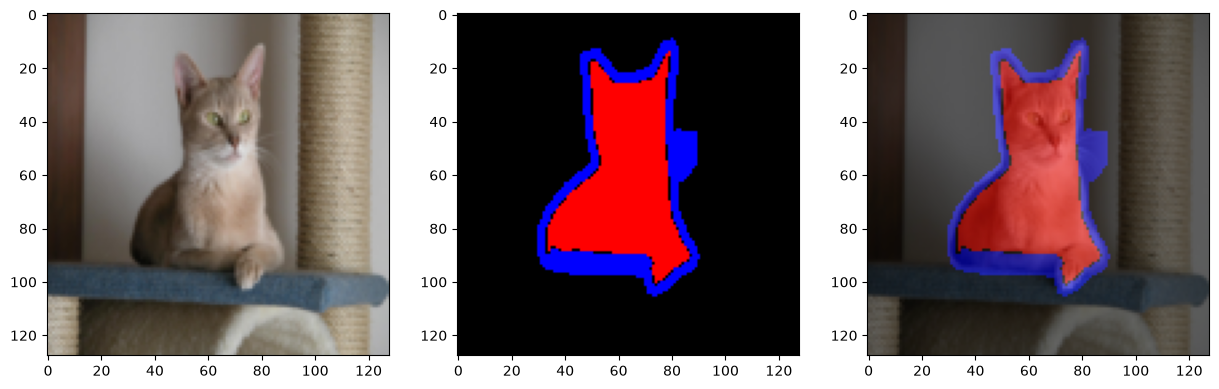

In [60]:
fig, axes = plt.subplots(1,3, figsize=(15,5))

for ax, arr in zip(axes, [img, mask_rgb, overlay]):
    ax.imshow(arr)

plt.show()

In [64]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels,  out_channels, kernel_size=3, padding=1), #, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1), #, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

In [70]:
# original:   64 -> 128 -> 256 -> 512; bottle neck -> 1024 -> 31 M
# light_unet: 16 ->  32 ->  64 -> 128; bottle neck -> 256  -> 2 M

class UNet(nn.Module):
    def __init__(self, in_channels=3, num_classes=3, base_channels=16):
        super(UNet, self).__init__()

        ch = base_channels

        # Энкодер
        self.enc1 = DoubleConv(in_channels, ch * 1)    # 16
        self.enc2 = DoubleConv(ch * 1, ch * 2)   # 32
        self.enc3 = DoubleConv(ch * 2, ch * 4)   # 64
        self.enc4 = DoubleConv(ch * 4, ch * 8)   # 128
        self.pool = nn.MaxPool2d(2)

        # Bootle neck
        self.bottleneck = DoubleConv(ch * 8, ch * 16)  # 256

        # Decoder
        self.up4 = nn.ConvTranspose2d(ch * 16, ch * 8, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(ch * 16, ch * 8)
        self.up3 = nn.ConvTranspose2d(ch * 8, ch * 4, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(ch * 8, ch * 4)
        self.up2 = nn.ConvTranspose2d(ch * 4, ch * 2, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(ch * 4, ch * 2)
        self.up1 = nn.ConvTranspose2d(ch * 2, ch * 1, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(ch * 2, ch * 1)

        # Exit
        self.out = nn.Conv2d(ch * 1, num_classes, 1)

    def forward(self, x):

        e1 = self.enc1(x)                   # 128
        e2 = self.enc2(self.pool(e1))       # 64
        e3 = self.enc3(self.pool(e2))       # 32
        e4 = self.enc4(self.pool(e3))       # 16

        b = self.bottleneck(self.pool(e4))  # 8

        d4 = self.up4(b)
        d4 = torch.cat([d4, e4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.out(d1)  # (B, NUM_CLASSES, H, W)

In [71]:
class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super(DiceLoss, self).__init__()
        self.smooth = smooth

    def forward(self, logits, labels):
        probs = F.softmax(logits, dim=1)
        labels_one_hot = F.one_hot(labels, NUM_CLASSES).permute(0,3,1,2).float()

        intersection = (probs * labels_one_hot).sum(dim=(2,3))
        union        = probs.sum(dim=(2,3)) + labels_one_hot.sum(dim=(2,3))

        dice = (2 * intersection + self.smooth) / (union + self.smooth)

        return 1 - dice.mean()

In [72]:
class CombinedLoss(nn.Module):
    def __init__(self, ce_weight=1.0, dice_weight=1.0):
        super(CombinedLoss, self).__init__()

        self.ce = nn.CrossEntropyLoss()
        self.dice = DiceLoss()
        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, labels):
        return self.ce_weight * self.ce(logits, labels) * self.dice_weight * self.dice(logits, labels)

In [75]:
model = UNet().to(DEVICE)
total_params = sum(p.numel() for p in model.parameters())
print(total_params / 1e6)

1.944083


In [76]:
criterion = CombinedLoss()

In [78]:
if AUGMENT:
    train_tf = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.ColorJitter(brightness=0.2, contrast=0.1, saturation=0.05, hue=0.15),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
else:
    train_tf = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

val_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [79]:
train_ds = PetDataset(root="input_data", split="trainval", image_tf=train_tf)
val_ds   = PetDataset(root="input_data", split="trainval", image_tf=val_tf)

In [ ]:
## debt about data loaders

In [ ]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)